# Boost semiconductor Pareto screen

A reproducible example using the reusable topology operation and TDB device curves. It compares semiconductor solutions under one fixed boost boundary: **100 V in, 200 V out, 1 kW, 20 kHz**.

This is a **conduction-loss screening example**, not a complete converter-loss design. Switching-energy curves in the local TDB examples are not measured at the 200 V switch voltage, so this notebook does not scale or substitute them. The Pareto objectives are measured-curve channel conduction loss, package-body volume, and a dated one-unit distributor price snapshot.

## Goal

Find non-dominated switch/rectifier package combinations at one fixed boost electrical operating point. Lower channel conduction loss, package volume, and component price are preferred. Switch gate voltage is candidate-specific to use an exact recorded TDB curve condition (15 V for CREE, 10 V for Infineon); the shared CREE diode bias is 0 V. Gate-drive loss and gate-supply hardware cost are excluded.

The candidates use the same CREE MOSFET record for the boost rectifier's body-diode curve. That rectifier is a separate physical package; the model object is shared read-only. One candidate uses the CREE MOSFET as both switch and rectifier, while the others use one or two Infineon switches and one CREE rectifier. Package count is included in cost and volume.

## Setup

Run from the repository's `ntbees2` Conda environment. The notebook reads existing example TDB JSON files through the core JSON loader and never saves or edits device records.

In [1]:
from math import prod
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from transistordatabase.core.repository import JsonTransistorLoader
from transistordatabase.topologies import calculate_topology_operating_point


def find_repo_root(start: Path = Path.cwd()) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "transistordatabase" / "examples" / "tdb_example"
        ).is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook from a checkout of transistordatabase")


repo_root = find_repo_root()
tdb_data = repo_root / "transistordatabase" / "examples" / "tdb_example"
loader = JsonTransistorLoader()

boundary = {
    "mode": "conduction-only",
    "conduction_regime": "CCM",
    "v_in": 100.0,
    "v_out": 200.0,
    "p_out": 1000.0,
    "f_sw": 20_000.0,
    "l_value": 1e-3,
    "c_out": 1e-3,
    "t_j": 25.0,
    "t_case": 60.0,
    "diode_v_g": 0.0,
    "parallel_switches": 1,
    "parallel_diodes": 1,
}

print(f"Repository: {repo_root}")
print(
    "Boundary: 100 V → 200 V, 1,000 W, 20 kHz; "
    "L = 1 mH, C = 1 mF, channel curves at Tj = 25 °C; fixed case/sink reference = 60 °C"
)

Repository: /home/tinix/claude_wsl/transistordatabase
Boundary: 100 V → 200 V, 1,000 W, 20 kHz; L = 1 mH, C = 1 mF, channel curves at Tj = 25 °C; fixed case/sink reference = 60 °C


## Steps

### 1. Load curve records and source-backed catalog data

Device electrical curves come from the checked-in TDB examples. Cost and physical package dimensions are notebook inputs with sources and an access date; they are not added to the TDB core schema. Volume is the maximum body-envelope product of length × width × height, excluding leads. Distributor prices are single-unit USD list prices and exclude tax and shipping.

In [2]:
device_names = ["CREE_C3M0060065J", "Infineon_IPBE65R050CFD7A"]
devices = {
    name: loader.load_from_json(tdb_data / f"{name}.json")
    for name in device_names
}

# Dimensions are maximum package-body dimensions from the linked manufacturer datasheets.
# The costs are one-unit U.S. DigiKey list prices accessed on 2026-10-02.
market_catalog = {
    "CREE_C3M0060065J": {
        "unit_cost_usd": 9.64,
        "body_dimensions_max_mm": {"length": 9.125, "width": 10.23, "height": 4.57},
        "price_url": "https://www.digikey.com/en/products/detail/wolfspeed-inc/C3M0060065J/12525328",
        "datasheet_url": "https://assets.wolfspeed.com/uploads/2024/01/Wolfspeed_C3M0060065J_data_sheet.pdf",
        "product_status_url": "https://www.wolfspeed.com/products/power/sic-mosfets/650v-silicon-carbide-mosfets/c3m0060065j/",
    },
    "Infineon_IPBE65R050CFD7A": {
        "unit_cost_usd": 10.78,
        "body_dimensions_max_mm": {"length": 9.45, "width": 10.20, "height": 4.50},
        "price_url": "https://www.digikey.com/en/products/detail/infineon-technologies/IPBE65R050CFD7AATMA1/13212427",
        "datasheet_url": "https://www.infineon.com/assets/row/public/documents/24/49/infineon-ipbe65r050cfd7a-datasheet-en.pdf",
        "product_status_url": "https://www.infineon.com/part/IPBE65R050CFD7A",
    },
}

for part_name, part_data in market_catalog.items():
    dimensions = part_data["body_dimensions_max_mm"]
    part_data["package_body_volume_mm3"] = prod(dimensions.values())

for device in devices.values():
    print(
        f"{device.metadata.name}: {device.metadata.type}, "
        f"Vabs={device.electrical_ratings.v_abs_max:g} V, "
        f"Iabs={device.electrical_ratings.i_abs_max:g} A, "
        f"switch curves={len(device.switch.channel_data)}, "
        f"rectifier curves={len(device.diode.channel_data)}"
    )

cree_switch_conditions = sorted(
    (curve.t_j, curve.v_supply, curve.v_g) for curve in devices["CREE_C3M0060065J"].switch.e_on_data
)
print("CREE turn-on curve conditions (Tj °C, Vdsupply V, Vg V):", cree_switch_conditions)
print("External market/package values are assumptions for this notebook only; see linked sources above.")

Transistor CREE_C3M0060065J generated / loaded successfully!
Transistor Infineon_IPBE65R050CFD7A generated / loaded successfully!
CREE_C3M0060065J: SiC-MOSFET, Vabs=650 V, Iabs=99 A, switch curves=15, rectifier curves=9
Infineon_IPBE65R050CFD7A: MOSFET, Vabs=650 V, Iabs=211 A, switch curves=16, rectifier curves=0
CREE turn-on curve conditions (Tj °C, Vdsupply V, Vg V): [(25, 400, 15), (25, 400, 15)]
External market/package values are assumptions for this notebook only; see linked sources above.


### 2. Define comparable semiconductor solutions

Each row uses the same boost electrical boundary and fixed CREE rectifier with its recorded 0 V gate-bias curve. Switch count and exact recorded switch gate voltage vary explicitly so each part uses an available TDB curve condition. Gate-drive losses and gate-supply hardware cost are excluded from these screening objectives.

In [3]:
candidate_specs = [
    {
        "label": "CREE ×1 + CREE rectifier ×1",
        "switch": "CREE_C3M0060065J",
        "diode": "CREE_C3M0060065J",
        "parallel_switches": 1,
        "parallel_diodes": 1,
        "v_g": 15.0,
    },
    {
        "label": "Infineon ×1 + CREE rectifier ×1",
        "switch": "Infineon_IPBE65R050CFD7A",
        "diode": "CREE_C3M0060065J",
        "parallel_switches": 1,
        "parallel_diodes": 1,
        "v_g": 10.0,
    },
    {
        "label": "Infineon ×2 + CREE rectifier ×1",
        "switch": "Infineon_IPBE65R050CFD7A",
        "diode": "CREE_C3M0060065J",
        "parallel_switches": 2,
        "parallel_diodes": 1,
        "v_g": 10.0,
    },
]

operating_point = calculate_topology_operating_point(
    "boost", {**boundary, "mode": "estimate"}, include_waveforms=False
)
print(
    f"Duty = {operating_point['calculated']['duty_cycle']:.3f}; "
    f"inductor current = {operating_point['calculated']['i_l_avg_a']:.2f} A avg, "
    f"{operating_point['calculated']['i_l_peak_a']:.2f} A peak; "
    f"switch blocking voltage = {operating_point['calculated']['v_switch_block_v']:.1f} V"
)

Duty = 0.500; inductor current = 10.00 A avg, 11.25 A peak; switch blocking voltage = 200.0 V


### 3. Calculate conduction losses and screen ratings

The voltage/current checks below are a basic nameplate screen only. They do not establish safe operating area, junction temperature, switching capability, or a finished design.

In [4]:
rows = []
for candidate in candidate_specs:
    switch_device = devices[candidate["switch"]]
    diode_device = devices[candidate["diode"]]
    parameters = {
        **boundary,
        "parallel_switches": candidate["parallel_switches"],
        "parallel_diodes": candidate["parallel_diodes"],
        "v_g": candidate["v_g"],
    }
    result = calculate_topology_operating_point(
        "boost",
        parameters,
        switch_transistor=switch_device,
        diode_transistor=diode_device,
        include_waveforms=False,
    )

    switch_peak_per_device_a = (
        result["calculated"]["i_l_peak_a"] / candidate["parallel_switches"]
    )
    diode_peak_per_device_a = (
        result["calculated"]["i_l_peak_a"] / candidate["parallel_diodes"]
    )
    blocking_voltage_v = result["calculated"]["v_switch_block_v"]
    ratings_pass = (
        switch_device.electrical_ratings.v_abs_max >= blocking_voltage_v
        and diode_device.electrical_ratings.v_abs_max >= blocking_voltage_v
        and switch_peak_per_device_a <= switch_device.electrical_ratings.i_abs_max
        and diode_peak_per_device_a <= diode_device.electrical_ratings.i_abs_max
    )

    switch_catalog = market_catalog[candidate["switch"]]
    diode_catalog = market_catalog[candidate["diode"]]
    total_cost_usd = (
        candidate["parallel_switches"] * switch_catalog["unit_cost_usd"]
        + candidate["parallel_diodes"] * diode_catalog["unit_cost_usd"]
    )
    total_volume_mm3 = (
        candidate["parallel_switches"] * switch_catalog["package_body_volume_mm3"]
        + candidate["parallel_diodes"] * diode_catalog["package_body_volume_mm3"]
    )
    rows.append(
        {
            **candidate,
            "conduction_loss_w": result["losses"]["total_w"],
            "switch_gate_voltage_v": candidate["v_g"],
            "temperatures": result["temperatures"],
            "cost_usd": total_cost_usd,
            "volume_mm3": total_volume_mm3,
            "ratings_pass": ratings_pass,
            "model_result": result,
        }
    )

if not all(row["ratings_pass"] for row in rows):
    raise ValueError("At least one candidate failed the basic voltage/current screen")

for row in rows:
    if row["model_result"]["model"]["mode"] != "conduction-only":
        raise AssertionError("The Pareto metric must remain explicitly conduction-only")
    if not row["model_result"]["losses"].get("switching_losses_included") is False:
        raise AssertionError("This example must not imply switching losses are included")

print(f"Evaluated {len(rows)} candidate package combinations; all pass the basic rating screen.")

Evaluated 3 candidate package combinations; all pass the basic rating screen.


### 4. Identify the three-objective Pareto frontier

A candidate is dominated if another candidate is no worse in all three objectives and strictly better in at least one. All objectives are minimized.

In [5]:
objective_names = ("conduction_loss_w", "volume_mm3", "cost_usd")
objective_values = np.array(
    [[row[name] for name in objective_names] for row in rows], dtype=float
)
pareto_mask = []
for index, values in enumerate(objective_values):
    no_worse = np.all(objective_values <= values, axis=1)
    strictly_better = np.any(objective_values < values, axis=1)
    dominated = np.any(no_worse & strictly_better)
    pareto_mask.append(not dominated)

for row, is_pareto in zip(rows, pareto_mask, strict=True):
    row["pareto"] = is_pareto

headers = ["Solution", "Switch gate voltage (V)", "Conduction loss (W)", "Package body volume (mm³)", "Cost (USD)", "Basic ratings", "Pareto"]
lines = ["| " + " | ".join(headers) + " |", "|---|---:|---:|---:|---:|---|---|"]
for row in rows:
    lines.append(
        "| {label} | {v_g:g} | {loss:.3f} | {volume:.1f} | ${cost:.2f} | {rating} | {pareto} |".format(
            label=row["label"],
            v_g=row["switch_gate_voltage_v"],
            loss=row["conduction_loss_w"],
            volume=row["volume_mm3"],
            cost=row["cost_usd"],
            rating="pass" if row["ratings_pass"] else "fail",
            pareto="yes" if row["pareto"] else "no",
        )
    )
display(Markdown("\n".join(lines)))

| Solution | Switch gate voltage (V) | Conduction loss (W) | Package body volume (mm³) | Cost (USD) | Basic ratings | Pareto |
|---|---:|---:|---:|---:|---|---|
| CREE ×1 + CREE rectifier ×1 | 15 | 18.565 | 853.2 | $19.28 | pass | yes |
| Infineon ×1 + CREE rectifier ×1 | 10 | 17.416 | 860.4 | $20.42 | pass | yes |
| Infineon ×2 + CREE rectifier ×1 | 10 | 16.500 | 1294.1 | $31.20 | pass | yes |

### Thermal coverage

The single-pass junction estimates use a fixed 60 °C case/sink reference. They are shown separately from the Pareto objectives. Missing or zero junction-to-case / case-to-sink resistance is reported as unavailable; no zero temperature rise is assumed.

In [6]:
from IPython.display import Markdown, display

thermal_lines = [
    "| Solution | Switch junction | Diode junction |",
    "|---|---|---|",
]
for row in rows:
    temperatures = row["temperatures"]

    def temperature_text(value, reason):
        if value is not None:
            return f"{value:.1f} °C"
        return f"Unavailable: {reason}"

    switch_reason = temperatures.get("switch_unavailable_reason")
    diode_reason = temperatures.get("diode_unavailable_reason")
    fallback_reason = temperatures.get("unavailable_reason") or "required resistance data unavailable"
    thermal_lines.append(
        f"| {row['label']} | "
        f"{temperature_text(temperatures.get('switch_c'), switch_reason or fallback_reason)} | "
        f"{temperature_text(temperatures.get('diode_c'), diode_reason or fallback_reason)} |"
    )

display(Markdown(
    "**Thermal diagnostics at a fixed 60 °C case/sink reference** "
    "(context only; not a Pareto objective):"
    + chr(10) * 2
    + chr(10).join(thermal_lines)
))

**Thermal diagnostics at a fixed 60 °C case/sink reference** (context only; not a Pareto objective):

| Solution | Switch junction | Diode junction |
|---|---|---|
| CREE ×1 + CREE rectifier ×1 | Unavailable: switch junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable | Unavailable: diode junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable |
| Infineon ×1 + CREE rectifier ×1 | Unavailable: switch junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable | Unavailable: diode junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable |
| Infineon ×2 + CREE rectifier ×1 | Unavailable: switch junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable | Unavailable: diode junction-to-case and case-to-sink thermal resistances must be finite and greater than zero; nonpositive TDB values are treated as unavailable |

### 5. Compare loss, volume, and cost

The three two-axis projections make the exact objectives easier to compare than a perspective-dependent 3D chart. Marker shape and label show joint three-objective Pareto status.

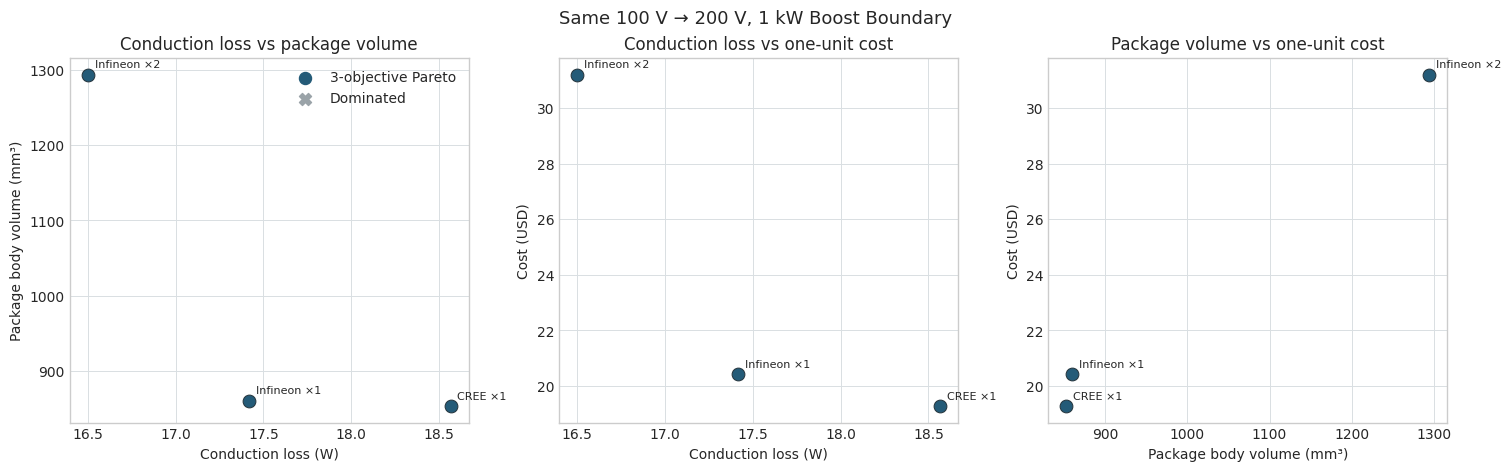

In [7]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
views = [
    ("conduction_loss_w", "volume_mm3", "Conduction loss vs package volume", "Conduction loss (W)", "Package body volume (mm³)"),
    ("conduction_loss_w", "cost_usd", "Conduction loss vs one-unit cost", "Conduction loss (W)", "Cost (USD)"),
    ("volume_mm3", "cost_usd", "Package volume vs one-unit cost", "Package body volume (mm³)", "Cost (USD)"),
]

for axis, (x_key, y_key, title, x_label, y_label) in zip(axes, views, strict=True):
    for row in rows:
        is_pareto = row["pareto"]
        axis.scatter(
            row[x_key],
            row[y_key],
            s=85,
            color="#245b78" if is_pareto else "#9aa3a8",
            marker="o" if is_pareto else "X",
            edgecolor="#24333b",
            linewidth=0.7,
            zorder=3,
        )
        short_label = row["label"].replace(" + CREE rectifier ×1", "")
        axis.annotate(short_label, (row[x_key], row[y_key]), xytext=(5, 5), textcoords="offset points", fontsize=8)
    axis.set_title(title)
    axis.set_xlabel(x_label)
    axis.set_ylabel(y_label)
    axis.grid(True, color="#d9dfe2", linewidth=0.7)

axes[0].scatter([], [], s=75, color="#245b78", marker="o", label="3-objective Pareto")
axes[0].scatter([], [], s=75, color="#9aa3a8", marker="X", label="Dominated")
axes[0].legend(frameon=False, loc="best")
fig.suptitle("Same 100 V → 200 V, 1 kW Boost Boundary", fontsize=13)
plt.show()

## Checks

This run checks one topology operating point, exact-temperature and candidate-specific gate channel-curve availability for each candidate, basic voltage and peak-current ratings, and a deterministic three-objective Pareto calculation. The browser/API model and the notebook call the same reusable Python operation.

### Loss and design limits

- The reported loss is **switch plus rectifier channel conduction only**, from the selected TDB curves at 25 °C. Switching energy, reverse recovery, gate-drive, dead-time, magnetic, capacitor, and parasitic losses are excluded.
- The strict `detailed` mode requires the relevant switching curves at the requested 200 V blocking condition. This example intentionally does not infer switching loss from curves measured at other voltages.
- The rating screen checks blocking voltage and peak current against TDB absolute ratings only. It does not check SOA, thermal limits, package cooling, reliability, or margin.
- Volume is a package-body bounding-box estimate, and cost is a dated one-unit distributor price. Neither includes board spacing, heatsinks, assembly, tax, or shipping.
- The curve-backed result is an ideal CCM operating point with channel losses evaluated at its ideal current waveform. It does not iterate the operating point for losses. Temperatures are reported only when positive junction-to-case and case-to-sink resistances are present; missing/zero thermal data is shown as unavailable, not replaced with zero rise. No electrothermal iteration is performed.

## Next Steps

Replace the dated market inputs with a current approved cost source, use package drawings that match the exact orderable part, and add diode parts with measured data suitable for the intended commutation conditions. A full-loss Pareto requires compatible switching-energy and reverse-recovery data at the real voltage, current, temperature, gate drive, and commutation device. Keep missing conditions ineligible instead of filling them by assumption.

### Source records

- TDB curve files: `transistordatabase/examples/tdb_example/CREE_C3M0060065J.json` and `transistordatabase/examples/tdb_example/Infineon_IPBE65R050CFD7A.json`.
- Wolfspeed C3M0060065J [datasheet](https://assets.wolfspeed.com/uploads/2024/01/Wolfspeed_C3M0060065J_data_sheet.pdf), [product status](https://www.wolfspeed.com/products/power/sic-mosfets/650v-silicon-carbide-mosfets/c3m0060065j/), and [DigiKey price listing](https://www.digikey.com/en/products/detail/wolfspeed-inc/C3M0060065J/12525328).
- Infineon IPBE65R050CFD7A [datasheet](https://www.infineon.com/assets/row/public/documents/24/49/infineon-ipbe65r050cfd7a-datasheet-en.pdf), [product status](https://www.infineon.com/part/IPBE65R050CFD7A), and [DigiKey price listing](https://www.digikey.com/en/products/detail/infineon-technologies/IPBE65R050CFD7AATMA1/13212427).

Market prices and availability were accessed on 2026-10-02 and can change.